# 17 液体神经网络：从松弛方程到可训练 LTC

前面的序列模型每前进一步就执行一次更新。若采样不规则，同一个输入可能持续 .05，也可能持续 .4 个时间单位；状态有多长时间响应这个输入，会直接改变下一次观测。后面的实验将把每段持续时间也交给模型。

## 1 从一个物理松弛过程开始

先看最简单的响应过程。h(t) 是随物理时间 t 变化的状态，u 是固定的平衡值，$\tau>0$ 是时间常数，单位与 t 相同：
$$\frac{dh}{dt}=\frac{u-h}{\tau}.$$
令 $v=h-u$，则 $dv/dt=-v/\tau$；积分得到 $v(t)=v(0)e^{-t/\tau}$，所以
$$h(t)=u+[h(0)-u]e^{-t/\tau}.$$
h 低于 u 时斜率为正，高于 u 时斜率为负；越接近平衡，变化越慢。经过一个时间常数，偏离平衡的量剩下原来的 $e^{-1}$。下图的三条曲线平衡值相同，差别只在接近平衡的速度。

In [1]:
from support import ROOT, check, show, style

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
torch.set_num_threads(1)
torch.manual_seed(17)
style()

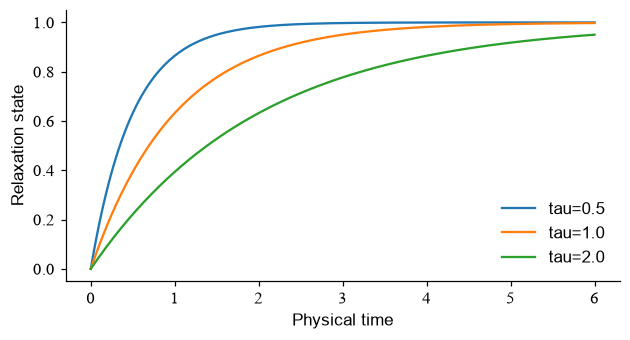

In [3]:
times = np.linspace(0, 6, 200)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for tau in [.5, 1., 2.]:
    state = 1-np.exp(-times/tau)
    ax.plot(times, state, label=f'tau={tau}')
ax.set(xlabel='Physical time', ylabel='Relaxation state'); ax.legend(frameon=False)
show(fig)

### 练习 q01：半衰时间与时间常数

h(0)=0、u=2、τ=3，计算 t=τ ln2 时的 h。

In [4]:
ex_q01_tau = 3.
ex_q01_time = None  # TODO
ex_q01_state = None  # TODO

In [5]:
# 填写上一格后，运行检查。
check('半衰时刻的状态', ex_q01_state, 1.)

待填写：半衰时刻的状态


<details>
<summary>提示</summary>

把 t/τ=ln2 代入解析式，指数项等于 1/2。

</details>

<details>
<summary>参考答案</summary>

```python
ex_q01_tau = 3.
ex_q01_time = ex_q01_tau*np.log(2.)
ex_q01_state = 2. + (0.-2.)*np.exp(-ex_q01_time/ex_q01_tau)
```

</details>

## 2 数值步长也参与计算

已有导数后，可以用一小段直线近似真实曲线。两次采样之间的时间差记作 $\Delta t$，显式 Euler 用起点斜率走一步：
$$h_{n+1}=h_n+\Delta t\,(u-h_n)/\tau.$$
减去 u 得 $h_{n+1}-u=(1-\Delta t/\tau)(h_n-u)$：对平衡值的偏离每步乘 $1-\Delta t/\tau$。这个系数的绝对值小于 1 时，误差逐步衰减，对应 $0<\Delta t/\tau<2$；绝对值超过 1 时，误差增长。

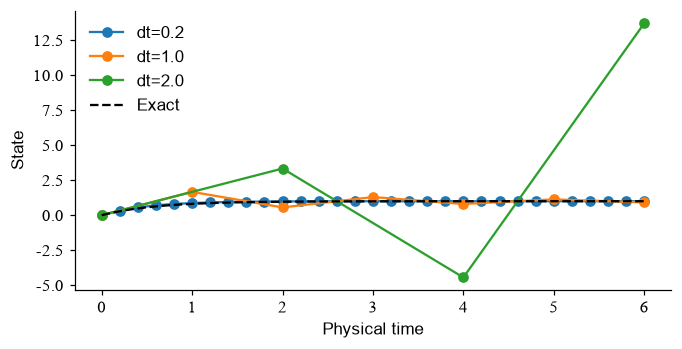

In [6]:
def euler_relax(dt, tau=.6, total=6.):
    grid = np.arange(round(total/dt)+1)*dt
    values = [0.]
    for _ in grid[1:]:
        values.append(values[-1]+dt*(1-values[-1])/tau)
    return grid, np.array(values)
fig, ax = plt.subplots(figsize=(7, 3.3))
for dt in [.2, 1., 2.]:
    grid, values = euler_relax(dt); ax.plot(grid, values, 'o-', label=f'dt={dt}')
ax.plot(times, 1-np.exp(-times/.6), 'k--', label='Exact')
ax.set(xlabel='Physical time', ylabel='State'); ax.legend(frameon=False)
show(fig)

图中 τ=.6。步长 .2 的偏离乘数为 2/3，状态逐步靠近平衡；步长 1 的乘数为 −2/3，状态越过平衡后交替接近；步长 2 的乘数为 −7/3，振荡幅度反而越来越大。三个数值轨迹使用同一条微分方程，差异来自离散步长。

### 练习 q02：手算 Euler 一步

h=0、u=2、τ=2、Δt=.5，计算下一状态与误差乘数。

In [7]:
ex_q02_next = None  # TODO
ex_q02_factor = None  # TODO
ex_q02_dt = .5

In [8]:
# 填写上一格后，运行检查。
check('Euler 下一状态', ex_q02_next, .5)
check('误差乘数', ex_q02_factor, .75)

待填写：Euler 下一状态
待填写：误差乘数


<details>
<summary>提示</summary>

增量是 Δt×(u−h)/τ；误差乘数是 1−Δt/τ。

</details>

<details>
<summary>参考答案</summary>

```python
ex_q02_dt = .5
ex_q02_next = 0.+ex_q02_dt*(2.-0.)/2.
ex_q02_factor = 1-ex_q02_dt/2.
```

</details>

## 3 让状态变化速度受到输入控制

固定 τ 的松弛过程在所有输入下按同一个尺度响应。液体神经网络让这个尺度也受输入和当前状态控制。本课实现 Liquid Time-Constant（LTC）的一种简化单元：u 为外部输入，h 为隐藏状态，A 为可学习的驱动水平，f 是依赖 u、h 的非负门函数：
$$\dot h=-\left(\frac1\tau+f(u,h)\right)h+f(u,h)A.$$
取 $f\ge0$，瞬时衰减系数为 $k=1/\tau+f$，相应有效时间常数为
$$\tau_{\rm eff}=\frac1{1/\tau+f}=\frac{\tau}{1+\tau f}.$$
将 f 暂时固定，方程可写成 $\dot h=-(h-h_*)/\tau_{\rm eff}$，其中平衡值为 $h_*=(fA)/(1/\tau+f)$。因此 f 改变时，接近平衡的速度与平衡位置会一起改变。沿轨迹计算 $\tau_{\rm eff}$，就能看到模型在不同输入和状态下使用了怎样的响应尺度。
下图先固定 h=0、τ=1.3，取门函数 $f(u,0)=\operatorname{softplus}(1.3u-.2)$。
$\operatorname{softplus}(z)=\log(1+e^z)$ 把实数平滑地映到正数；`np.logaddexp(0,z)` 稳定计算同一个表达式。
[LTC 原论文](https://arxiv.org/abs/2006.04439) 从这种依赖状态的动力学构造可训练网络。

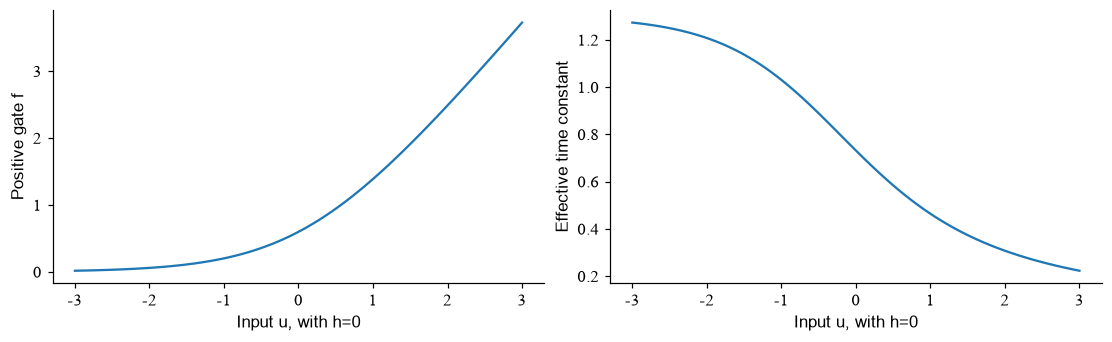

In [9]:
external = np.linspace(-3, 3, 100)
positive_gate = np.logaddexp(0., 1.3*external-.2)
tau_effective = 1/(1/1.3 + positive_gate)
fig, axes = plt.subplots(1, 2, figsize=(10, 3), layout='constrained')
axes[0].plot(external, positive_gate); axes[0].set(xlabel='Input u, with h=0', ylabel='Positive gate f')
axes[1].plot(external, tau_effective); axes[1].set(xlabel='Input u, with h=0', ylabel='Effective time constant')
show(fig)

这里固定了 h，因此横轴只改变外部输入。门 f 增大时，分母 1/τ+f 增大，有效时间常数缩短。恢复状态依赖以后，即使两次输入相同，旧状态不同也会产生不同的门值。

### 练习 q03：分开基础 τ 与有效 τ

基础 τ=2，三个门值为 [0,.5,1.5]，计算对应有效时间常数。

In [10]:
ex_q03_gate = np.array([0., .5, 1.5])
ex_q03_effective = None  # TODO
ex_q03_tau = 2.

In [11]:
# 填写上一格后，运行检查。
check('三种有效时间常数', ex_q03_effective, [2.,1.,.5])

待填写：三种有效时间常数


<details>
<summary>提示</summary>

计算 1/(1/τ+f)，数组里的每个 f 各算一次。

</details>

<details>
<summary>参考答案</summary>

```python
ex_q03_gate = np.array([0., .5, 1.5])
ex_q03_tau = 2.
ex_q03_effective = 1/(1/ex_q03_tau+ex_q03_gate)
```

</details>

## 4 把线性状态项放在新时刻

要从导数得到下一状态，需要选择一个数值更新式。在旧状态计算 $f_n=f(u_n,h_n)$，并在这一个子步内固定该门值；把线性衰减作用到新状态：
$$h_{n+1}=h_n+\Delta t[-(1/\tau+f_n)h_{n+1}+f_nA].$$
把所有含新状态的项移到左边，再除以系数，得到半隐式步：
$$h_{n+1}=\frac{h_n+\Delta t f_n A}{1+\Delta t(1/\tau+f_n)}.$$
当 $\Delta t>0$ 时，分母大于 1；固定门以后，旧状态的直接系数为这个分母的倒数。门在子步开始时仍由旧 h 算出，所以回传梯度时还需要经过 $h_n\to f_n\to h_{n+1}$。下面先看前向数值，再把这条支路的导数接上。

In [12]:
h_old, tau, gate, drive, dt = 1., 2., .5, 3., .2
numerator = h_old + dt*gate*drive
denominator = 1+dt*(1/tau+gate)
semi_implicit = numerator/denominator
explicit = h_old+dt*(-(1/tau+gate)*h_old+gate*drive)
print('numerator / denominator:', numerator, denominator)
print('semi-implicit / explicit:', semi_implicit, explicit)

numerator / denominator: 1.3 1.2
semi-implicit / explicit: 1.0833333333333335 1.1


### 练习 q04：从移项写出一步更新

沿用上一格的 h、τ、f、A、Δt，从分子、分母计算半隐式结果。

In [13]:
ex_q04_h, ex_q04_tau, ex_q04_f = 1., 2., .5
ex_q04_A, ex_q04_dt = 3., .2
ex_q04_next = None  # TODO

In [14]:
# 填写上一格后，运行检查。
check('半隐式一步', ex_q04_next, 13/12)

待填写：半隐式一步


<details>
<summary>提示</summary>

分子是 1+.2×.5×3；分母是 1+.2×(.5+.5)。

</details>

<details>
<summary>参考答案</summary>

```python
ex_q04_h, ex_q04_tau, ex_q04_f = 1., 2., .5
ex_q04_A, ex_q04_dt = 3., .2
ex_q04_next = (ex_q04_h+ex_q04_dt*ex_q04_f*ex_q04_A)/(1+ex_q04_dt*(1/ex_q04_tau+ex_q04_f))
```

</details>

这一格的常数给出 $h_*=1.5$、$\tau_{\rm eff}=1$。冻结 f 后跨越时间 T，可以写出精确参考解：$h(T)=h_*+[h(0)-h_*]e^{-T/\tau_{\rm eff}}$。

将同一段 T=1 分成更多半隐式子步，每个子步只走较短的一段，比较终点与精确解的距离。这个对照单独检验积分误差；后面的状态依赖单元会在每个子步重新计算门。

In [15]:
exact_end = 1.5 + (1.-1.5)*np.exp(-1.)
integration_errors = []
for substeps in [1, 2, 4, 8, 16, 32]:
    value, small_dt = 1., 1./substeps
    for _ in range(substeps):
        value = (value+small_dt*.5*3)/(1+small_dt*(1/2+.5))
    integration_errors.append(abs(value-exact_end))
print('errors, 1 to 32 substeps:', integration_errors)

errors, 1 to 32 substeps: [np.float64(0.06606027941427883), np.float64(0.03828250163650093), np.float64(0.020860279414278704), np.float64(0.01093245097875184), np.float64(0.005602945373247348), np.float64(0.002837210159309267)]


## 5 给参数施加可微的正值约束

优化器直接加减参数，而时间常数需要保持为正。让原始参数 r 在实数范围更新，再用 $\tau=\operatorname{softplus}(r)+0.05$ 得到实际时间常数，其中 $\operatorname{softplus}(r)=\log(1+e^r)$。损失对 r 的梯度会经过这个可微变换。

门取 $f(u,h)=\operatorname{softplus}(w_u u+w_h h+b)$。基础 τ、输入权重、状态权重、偏置与驱动 A 都参加学习。同一组训练好的参数沿序列反复使用；每一步的 u、h 改变时，门 f 和有效 τ 也随之改变。

### 练习 q05：原始参数改变，时间常数仍为正

原始参数为 [−3,0,2]，用 PyTorch softplus 加 .05，返回三个时间常数。

In [16]:
ex_q05_raw = torch.tensor([-3.,0.,2.])
ex_q05_tau = None  # TODO
ex_q05_offset = .05

In [17]:
# 填写上一格后，运行检查。
check('正时间常数', ex_q05_tau, np.logaddexp(0.,[-3.,0.,2.])+.05)

待填写：正时间常数


<details>
<summary>提示</summary>

F.softplus(raw) 实现数值稳定的 log(1+exp(raw))。

</details>

<details>
<summary>参考答案</summary>

```python
ex_q05_raw = torch.tensor([-3.,0.,2.])
ex_q05_offset = .05
ex_q05_tau = F.softplus(ex_q05_raw)+ex_q05_offset
```

</details>

### 一个子步的完整状态导数

旧 h 有两条路影响新状态：一条直接进入分子，另一条先改变门 f，再同时改变分子与分母。

记分母为 $D=1+\Delta t(1/\tau+f)$，分子为 $N=h+\Delta t fA$，新状态为 $h_+=N/D$。先将 h 固定、把 f 当中间变量，用商法则得到
$$\frac{\partial h_+}{\partial f}=\frac{\Delta t A D-N\Delta t}{D^2}
=\frac{\Delta t(A-N/D)}D
=\frac{\Delta t(A-h_+)}D.$$
再令 $z=w_u u+w_hh+b$。softplus 的导数是 $\sigma(z)$，因此门对旧状态的导数为 $f_h=w_h\sigma(z)$。将两条路径的贡献相加：
$$\frac{d h_+}{d h}=\frac1D+\frac{\Delta t(A-h_+)}D f_h.$$
第一项来自分子中的直接 h，第二项来自门的变化。第二项的符号取决于 $A-h_+$ 与状态权重 $w_h$，会增强或抵消第一项。下一格用自动微分对照这两项相加的结果。

In [18]:
h_grad = torch.tensor(.4, dtype=torch.float64, requires_grad=True)
u_grad, dt_grad, tau_grad, A_grad = .3, .2, 1.3, 1.4
z_grad = 1.3*u_grad-.4*h_grad-.2
f_grad = F.softplus(z_grad)
denominator_grad = 1+dt_grad*(1/tau_grad+f_grad)
h_plus = (h_grad+dt_grad*f_grad*A_grad)/denominator_grad
analytic_grad = 1/denominator_grad + dt_grad*(A_grad-h_plus)/denominator_grad*(-.4*torch.sigmoid(z_grad))
auto_grad = torch.autograd.grad(h_plus, h_grad)[0]
check('包含门支路的状态导数', auto_grad, analytic_grad.detach(), atol=1e-10)

通过：包含门支路的状态导数


### 练习 q06：冻结门与完整梯度分别是多少

若 D=1.4、Δt=.2、A=1.5、新状态=.6、f_h=−.1，分别求直接通路和总导数。

In [19]:
ex_q06_direct = None  # TODO
ex_q06_total = None  # TODO
ex_q06_D = 1.4

In [20]:
# 填写上一格后，运行检查。
check('直接通路', ex_q06_direct, 1/1.4)
check('完整导数', ex_q06_total, .982/1.4)

待填写：直接通路
待填写：完整导数


<details>
<summary>提示</summary>

直接项 1/D；再加 Δt(A−h_new)f_h/D。

</details>

<details>
<summary>参考答案</summary>

```python
ex_q06_D = 1.4
ex_q06_direct = 1/ex_q06_D
ex_q06_total = ex_q06_direct+.2*(1.5-.6)/ex_q06_D*(-.1)
```

</details>

再让原始时间常数参数也参加梯度核对。`gradcheck` 对每个输入做微小正负扰动，用中心差分比较自动微分；这里同时检查状态、外部输入和原始 τ 参数。

In [21]:
def parameterized_liquid_step(h, u, raw_tau):
    tau = F.softplus(raw_tau)+.05
    f = F.softplus(1.3*u-.4*h-.2)
    return (h+.2*f*1.4)/(1+.2*(1/tau+f))
gradient_inputs = tuple(torch.tensor(v, dtype=torch.float64, requires_grad=True)
                        for v in [.4, .3, .2])
liquid_gradient_ok = torch.autograd.gradcheck(parameterized_liquid_step, gradient_inputs,
                                             eps=1e-6, atol=1e-5)
check('状态、输入和 tau 原始参数差分核对', liquid_gradient_ok, True)

通过：状态、输入和 tau 原始参数差分核对


## 6 构造不规则时间间隔的数据

现在把一段更新接成整条序列。每条独立序列有 24 段，第 t 段输入 $u_t$ 在该段内保持常值，持续时间 $\Delta t_t$ 独立均匀取自 [.05,.4]。相同的输入幅度遇到不同的持续时间，就会留下不同的状态变化。

用已知动力学生成参考状态：$\tau=1.3$、$A=1.4$、$f=\operatorname{softplus}(1.3u-0.4h-0.2)$。参考积分每段使用 12 个 RK4 小步，并记录段末状态。模型收到输入幅度和时间间隔，学习重现这些状态。

In [22]:
rng = np.random.default_rng(171)
liquid_inputs = rng.uniform(-1., 1., size=(224,24,1))
liquid_dt = rng.uniform(.05, .4, size=(224,24,1))
def reference_rhs(h, u):
    f = np.logaddexp(0., 1.3*u-.4*h-.2)
    return -(1/1.3+f)*h+f*1.4

生成参考轨迹时，RK4 先估计小步起点、两个中点和终点的斜率，再按 1、2、2、1 加权。每次估计都会用新的中间状态重新计算门。同一段内 u 保持不变，h 在 12 个小步中连续推进；段末值随后成为监督目标。

In [23]:
reference_state, reference_trajectory = np.zeros((224,1)), []
for t in range(24):
    u, step = liquid_inputs[:,t], liquid_dt[:,t]/12
    for _ in range(12):
        k1 = reference_rhs(reference_state, u)
        k2 = reference_rhs(reference_state+step*k1/2, u)
        k3 = reference_rhs(reference_state+step*k2/2, u)
        k4 = reference_rhs(reference_state+step*k3, u)
        reference_state = reference_state+step*(k1+2*k2+2*k3+k4)/6
    reference_trajectory.append(reference_state.copy())

In [24]:
liquid_X = torch.tensor(liquid_inputs, dtype=torch.float32)
liquid_steps = torch.tensor(liquid_dt, dtype=torch.float32)
liquid_Y = torch.tensor(np.stack(reference_trajectory, axis=1), dtype=torch.float32)
train_X, test_X = liquid_X[:168], liquid_X[168:]
train_dt, test_dt = liquid_steps[:168], liquid_steps[168:]
train_Y, test_Y = liquid_Y[:168], liquid_Y[168:]
print('independent training/test sequences:', len(train_X), len(test_X))

independent training/test sequences:

 168 56


## 7 把公式逐行写成可训练的单元

x 为 `(B,1)`，h 为 `(B,H)`，dt 为 `(B,1)`；拼接 `[x,h]` 后用共享线性层算出 H 个非负门。基础 τ 与驱动 A 各有 H 个分量，按刚才的式子逐分量更新状态。

每个采样间隔划为四个子步，每次用更新后的 h 重新计算 f。下面默认 H=1，使模型状态能与生成方程中的标量直接对照。类中的 `forward` 对应一段物理时间，外层序列循环再把 24 段接起来。

In [25]:
class MinimalLTCCell(nn.Module):
    def __init__(self, hidden=1, substeps=4):
        super().__init__()
        self.hidden, self.substeps = hidden, substeps
        self.gate = nn.Linear(1+hidden, hidden)
        self.raw_tau = nn.Parameter(torch.zeros(hidden))
        self.drive = nn.Parameter(torch.ones(hidden))
    @property
    def tau(self):
        return F.softplus(self.raw_tau)+.05
    def forward(self, x, h, dt):
        small_dt = dt/self.substeps
        for _ in range(self.substeps):
            f = F.softplus(self.gate(torch.cat([x,h], dim=-1)))
            h = (h+small_dt*f*self.drive)/(1+small_dt*(1/self.tau+f))
        return h

In [26]:
class LiquidSequence(nn.Module):
    def __init__(self):
        super().__init__()
        self.cell = MinimalLTCCell()
    def forward(self, X, dt):
        h = X.new_zeros(X.shape[0], self.cell.hidden)
        states = []
        for t in range(X.shape[1]):
            h = self.cell(X[:,t], h, dt[:,t])
            states.append(h)
        return torch.stack(states, dim=1)

每段的四个子步都保留在计算图中。训练损失比较 24 个段末状态，反向传播会穿过这些数值更新，回到门的权重、原始时间常数与驱动 A。梯度检验中拆开的直接通路和门通路，在这里都会参加参数学习。

In [27]:
torch.manual_seed(172)
liquid_model = LiquidSequence()
liquid_optimizer = torch.optim.Adam(liquid_model.parameters(), lr=.025)
liquid_losses = []
for epoch in range(170):
    liquid_optimizer.zero_grad()
    liquid_loss = (liquid_model(train_X, train_dt)-train_Y).square().mean()
    liquid_loss.backward()
    liquid_optimizer.step()
    liquid_losses.append(liquid_loss.item())

In [28]:
with torch.no_grad():
    liquid_prediction = liquid_model(test_X, test_dt)
    liquid_mse = (liquid_prediction-test_Y).square().mean().item()
print('test MSE:', liquid_mse)
print('learned base tau / drive:', liquid_model.cell.tau.detach(), liquid_model.cell.drive.detach())
print('gate input/state weights:', liquid_model.cell.gate.weight.detach())
physical_times = test_dt[0,:,0].cumsum(dim=0).numpy()

test MSE: 0.00017787257093004882
learned base tau / drive: tensor([1.0445]) tensor([1.2117])
gate input/state weights: tensor([[1.4178, 0.0107]])


比较预测时，用真实 Δt 累加得到物理时间轴：时间点之间的横向距离保留了采样疏密。逐段读取门时，使用该段输入和起点的预测状态，算出该段起始的有效时间常数；下图将这个值标在对应段的终点，与输入段及状态点对齐。

In [29]:
with torch.no_grad():
    previous_states = torch.cat([torch.zeros(1,1), liquid_prediction[0,:-1]], dim=0)
    observed_gate = F.softplus(liquid_model.cell.gate(torch.cat([test_X[0], previous_states], dim=1)))
    observed_tau = 1/(1/liquid_model.cell.tau+observed_gate)

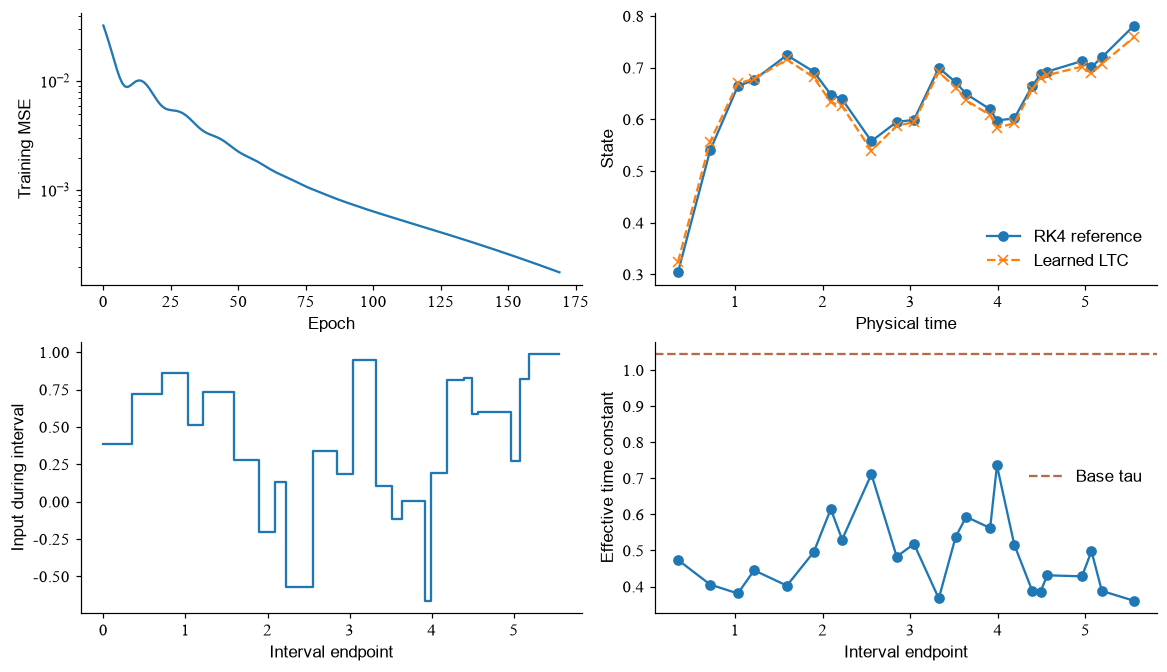

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 6), layout='constrained')
axes[0,0].semilogy(liquid_losses); axes[0,0].set(xlabel='Epoch', ylabel='Training MSE')
axes[0,1].plot(physical_times, test_Y[0,:,0], 'o-', label='RK4 reference')
axes[0,1].plot(physical_times, liquid_prediction[0,:,0], 'x--', label='Learned LTC')
axes[0,1].set(xlabel='Physical time', ylabel='State'); axes[0,1].legend(frameon=False)
input_plot_times = np.r_[0., physical_times]
input_plot_values = torch.cat([test_X[0,:1,0], test_X[0,:,0]])
axes[1,0].step(input_plot_times, input_plot_values, where='pre')
axes[1,0].set(xlabel='Interval endpoint', ylabel='Input during interval')
axes[1,1].plot(physical_times, observed_tau[:,0], 'o-')
axes[1,1].axhline(liquid_model.cell.tau.item(), ls='--', color='#B66A47', label='Base tau')
axes[1,1].set(xlabel='Interval endpoint', ylabel='Effective time constant')
axes[1,1].legend(frameon=False)
show(fig)

右上图比较同一条测试序列的段末状态，左下图给出各段持续的输入。右下图的虚线是训练后固定的基础 τ，实线点是各段起始状态下的有效 τ。输入和旧状态一起改变门，所以基础参数固定后，响应尺度仍随序列变化。

## 8 接到论文中的三类连续时间模型

| 模型 | 本课对应的计算对象 |
|---|---|
| [Neural ODE](https://arxiv.org/abs/1806.07366) | 用网络参数化 $\dot h=F_\theta(h,u,t)$，再积分 |
| [LTC](https://arxiv.org/abs/2006.04439) | 用泄漏与非负状态依赖门共同决定瞬时衰减系数，数值求解 |
| [CfC](https://arxiv.org/abs/2106.13898) | 从 LTC 动力学近似推导显含时间间隔的闭式更新结构 |

本课每个状态使用一个非负门；作者 [ncps](https://github.com/mlech26l/ncps) 的 `ltc_cell.py` 按多条突触分别求电导与反转电位贡献，分子与分母都含跨突触求和。阅读实现时，先找到有效电容与时间步组成的 `cm_t`，再看泄漏 `gleak`、驱动项 `w_numerator` 与衰减项 `w_denominator`，将多条突触的求和接回本课的分子、分母。

## 9 将预测误差拆成可以检验的问题

先冻结训练好的参数，将每段子步数从 4 改为 1、2、8、16。比较同一测试序列的 MSE 与计算时间，观察增加积分精度能改变多少预测误差。这个实验直接接着前面的固定门积分对照。

然后保留真实采样时间，只把模型收到的 Δt 替换成训练集平均值。将误差按实际间隔长短分组，就能检查模型是否用到了时间间隔信息。

门的状态依赖可以单独拿出来检验：保持参数量接近，把门中的状态系数固定为零，再重新训练多次。比较输入依赖与输入加状态依赖两种门的误差和有效 τ 轨迹。

最后对照生成方程中的 τ=1.3、A=1.4，记录多次训练学到的参数。若预测接近而参数变化较大，可以继续改变观测噪声与时间范围，检查现有轨迹提供了多少参数辨识信息。接到实验记录时，可用相同划分比较物理松弛基线、RNN 与 LTC，再改变采样密度观察差异。

## 带着问题读原文

[Hasani 等：Liquid Time-Constant Networks，式 (1) 与融合求解步](https://arxiv.org/html/2006.04439v4)

从 ODE 重新移项得到半隐式步，标出哪些状态项在旧时刻计算。论文时间常数界的证明对门函数用了什么有界性条件？本课 softplus 门满足哪些条件？在作者 ncps 代码中找到对应的多突触求和，解释简化单门与其参数化的关系。